# M11 · Rider-safety models

**Goal:** beat the M10 rule baseline (catch incidents earlier, with fewer false alarms) without losing recall.

| Detector | Idea |
|---|---|
| Rules | M10 baseline: four readable thresholds |
| Isolation Forest | Unsupervised: learns what normal looks like, flags the unusual. No labels needed |
| LightGBM | Supervised gradient boosting on 27 features (current minute + ride history) |
| **Hybrid** | Deterministic rules (GPS spoofing, wrong drop-off) **+** LightGBM for the ambiguous cases |

**Fair comparison.** Every detector gets its alert threshold the same way: on the validation day, the highest recall
within the *rules' own* false-alarm budget. **Final verdict** on a holdout week (second simulator run, different seed,
the following week, 41,578 trips) that was never used during development, with bootstrap confidence intervals.

Train with `python -m ml.train` (logs to MLflow, registers `rideops_safety_detector`); this notebook loads the result.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from ml import plot_style as ps
from ml.dataset import MODEL_FEATURES, load_windows, matrix
from ml.detector import SafetyDetector
from ml.labels import INCIDENT_TYPES
from ml.metrics import bootstrap_ci, detections, evaluate, paired_bootstrap, threshold_curve
from ml.rules import apply_rules
from ml.train import DETECTOR_PATH, HOLDOUT_RUN, MODEL_DIR, fit_isolation_forest, iso_score

ps.use()
pd.set_option("display.width", 200, "display.max_columns", 30, "display.precision", 3, "display.max_colwidth", 120)

detector = SafetyDetector.load(DETECTOR_PATH)
dev, dev_labels, _ = load_windows()
hold, hold_labels, hold_rides = load_windows(HOLDOUT_RUN)
card = json.loads((MODEL_DIR / "detector_card.json").read_text())
print(f"detector {detector.version}: threshold {detector.threshold:.4f}, {len(detector.features)} features, params {card['params']}")
print(f"holdout week: {hold['ride_id'].nunique():,} trips, {len(hold_labels)} incidents, {len(hold):,} windows")

detector 4cddc314: threshold 0.9864, 27 features, params {'scale_pos_weight': 20, 'num_leaves': 15}
holdout week: 41,578 trips, 845 incidents, 920,683 windows


## 1 · Holdout verdict

All four detectors at the same false-alarm budget (set on the validation day), measured once on the holdout week.

In [2]:
iso = fit_isolation_forest(dev[(dev["split"] == "train") & ~dev["after_incident"]])
comparison = pd.read_csv(MODEL_DIR / "comparison.csv")
hold_alerts = {
    "rules": apply_rules(hold)["alert"],
    "hybrid": detector.alerts(hold)["alert"],
}
hold_scored = hold.assign(risk=detector.risk(hold))
comparison.set_index(["set", "detector"])[["recall", "precision", "false_alarms_per_1k_trips", "median_delay_s"]
                                          + [f"recall_{t}" for t in INCIDENT_TYPES]]

recall  precision  false_alarms_per_1k_trips  median_delay_s  recall_route_deviation  recall_long_stop  recall_wrong_dropoff  recall_possible_crash  recall_gps_spoofing
set     detector                                                                                                                                                                                  
test    rules              0.966      0.919                      1.688         304.602                   0.925             0.952                 1.000                  1.000                1.000
        isolation_forest   0.381      0.726                      2.302         367.707                   0.700             0.048                 0.000                  0.250                0.444
        lightgbm           0.864      0.953                      0.767         267.627                   0.750             1.000                 0.786                  1.000                0.889
        hybrid             0.915      0.956                      0.767         264.113                   0.750             1.000                 1.000                  1.000                1.000
holdout rules              0.933      0.919                      1.539         326.329                   0.873             0.887                 1.000                  1.000                0.994
        isolation_forest   0.308      0.734                      1.660         382.614                   0.684             0.014                 0.000                  0.168                0.437
        lightgbm           0.882      0.943                      0.986         287.658                   0.844             0.946                 0.622                  1.000                0.952
        hybrid             0.940      0.946                      0.986         280.966                   0.844             0.946                 1.000                  1.000                0.994

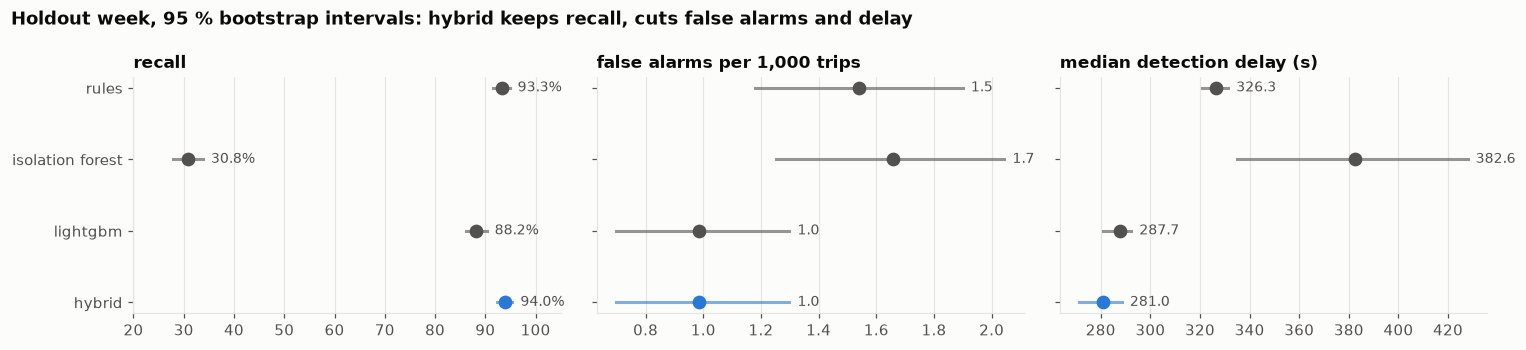

In [3]:
ci = pd.read_csv(MODEL_DIR / "holdout_ci.csv", index_col=[0, 1])
order = ["rules", "isolation_forest", "lightgbm", "hybrid"]
metrics = [("recall", "recall", 100, "%"), ("false_alarms_per_1k_trips", "false alarms per 1,000 trips", 1, ""),
           ("median_delay_s", "median detection delay (s)", 1, "")]

fig, axes = plt.subplots(1, 3, figsize=(14, 3.2))
for ax, (m, title, scale, unit) in zip(axes, metrics):
    for y, name in enumerate(order):
        v, lo, hi = (ci.loc[(name, m), c] * scale for c in ("value", "ci_low", "ci_high"))
        color = ps.ACCENT if name == "hybrid" else ps.NORMAL_COLOR
        ax.plot([lo, hi], [y, y], color=color, linewidth=2, alpha=0.6)
        ax.plot(v, y, "o", color=color, markersize=8)
        ax.text(hi, y, f"  {v:.1f}{unit}", va="center", fontsize=9, color=ps.INK_MUTED)
    ax.set_yticks(range(len(order)), [o.replace("_", " ") for o in order] if ax is axes[0] else [""] * len(order))
    ax.set_title(title); ax.grid(axis="y", visible=False); ax.invert_yaxis()
axes[0].set_xlim(20, 105)
fig.suptitle("Holdout week, 95 % bootstrap intervals: hybrid keeps recall, cuts false alarms and delay",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout(); ps.save(fig, "11_holdout_verdict")

**Is the hybrid really better than the rules?** Two separate intervals can overlap even when one detector is reliably
better. The proper test is **paired**: both detectors scored on the *same* resampled rides, interval of the difference.

In [4]:
paired = paired_bootstrap(hold, hold_alerts["rules"], hold_alerts["hybrid"], hold_labels, n_boot=2000)
paired.rename(index=lambda m: f"hybrid - rules: {m}")

,difference,ci_low,ci_high,significant
hybrid - rules: recall,0.007,-0.010,0.023,False
hybrid - rules: false_alarms_per_1k_trips,-0.553,-0.962,-0.120,True
hybrid - rules: median_delay_s,-45.363,-52.768,-40.065,True


## 2 · Why the unsupervised model fails

Isolation Forest catches about 30 % of incidents at the same false-alarm cost. It flags *unusual* trips, and unusual is
not the same as *unsafe*. Which normal windows does it find most unusual?

In [5]:
hold_iso = iso_score(iso, hold)
normal = hold[~hold["is_incident"] & ~hold["after_incident"]]
top_unusual = normal.loc[hold_iso[normal.index].nlargest(500).index]
cols = ["speed_max_kmh", "speed_mean_kmh", "minutes_into_ride", "dist_to_dropoff_last_m", "stop_run_max_s", "dist_off_route_max_m"]
pd.DataFrame({"all normal windows (median)": normal[cols].median(),
              "500 most 'unusual' normal windows (median)": top_unusual[cols].median()}).round(1)

,all normal windows (median),500 most 'unusual' normal windows (median)
speed_max_kmh,18.8,16.5
speed_mean_kmh,16.2,9.0
minutes_into_ride,12.0,10.5
dist_to_dropoff_last_m,2543.5,1609.8
stop_run_max_s,0.0,20.0
dist_off_route_max_m,6.4,470.5


In [6]:
caught_by_type = (detections(hold.assign(alert=hold_iso > np.quantile(hold_iso, 0.995)), hold_labels)
                  .groupby("incident_type")["detected"].mean().reindex(INCIDENT_TYPES))
caught_by_type.to_frame("Isolation Forest recall at its top 0.5 % of windows")

,Isolation Forest recall at its top 0.5 % of windows
incident_type,
route_deviation,0.922
long_stop,0.086
wrong_dropoff,0.000
possible_crash,0.723
gps_spoofing,0.928


Two failures. Its most "unusual" normal windows are **innocent detours** (median 470 m off route), so its alert budget
is spent on harmless trips. And a long stop is a car **standing still**, a perfectly ordinary pattern for an unsupervised
model (traffic lights, pick-ups): even at its top 0.5 % of windows it finds under 10 % of long stops. Only labels can
teach that standing still for 6 minutes mid-trip is dangerous. **Lesson: when ground truth exists, use it.**
Unsupervised detection still earns its place for incident types nobody has labelled yet.

## 3 · Trade-off: recall vs false alarms

The threshold is a business decision: every point on the curve is a different safety-team workload.
Holdout week, with the deterministic rules always on for the hybrid.

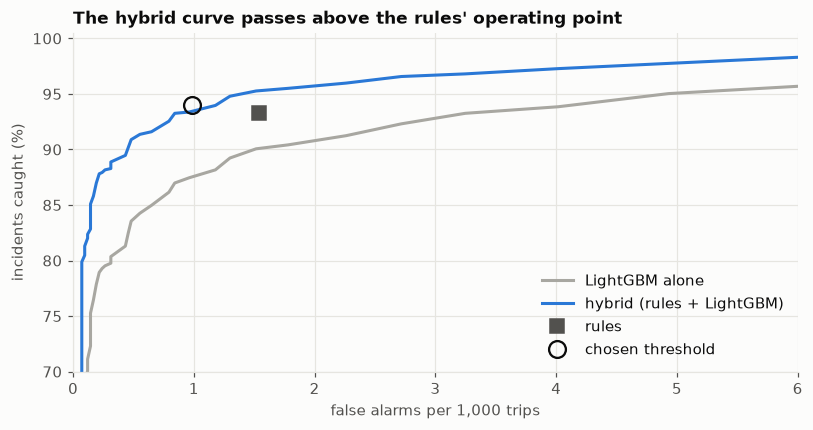

In [7]:
from ml.detector import DETERMINISTIC_RULES
from ml.rules import rule_flags

thresholds = np.unique(np.quantile(hold_scored["risk"], 1 - np.geomspace(5e-2, 1e-6, 400)))
curve_lgbm = threshold_curve(hold, hold_scored["risk"], hold_labels, thresholds)
curve_hybrid = threshold_curve(hold, hold_scored["risk"], hold_labels, thresholds,
                               forced=rule_flags(hold)[DETERMINISTIC_RULES].any(axis=1))
rules_point = evaluate(hold.assign(alert=hold_alerts["rules"]), hold_labels)
chosen = threshold_curve(hold, hold_scored["risk"], hold_labels, np.array([detector.threshold]),
                         forced=rule_flags(hold)[DETERMINISTIC_RULES].any(axis=1)).iloc[0]

fig, ax = plt.subplots(figsize=(8.5, 4))
ax.plot(curve_lgbm["false_alarms_per_1k_trips"], 100 * curve_lgbm["recall"], color=ps.HARD_NEGATIVE_COLOR, label="LightGBM alone")
ax.plot(curve_hybrid["false_alarms_per_1k_trips"], 100 * curve_hybrid["recall"], color=ps.ACCENT, label="hybrid (rules + LightGBM)")
ax.plot(rules_point["false_alarms_per_1k_trips"], 100 * rules_point["recall"], "s", color=ps.NORMAL_COLOR, markersize=9, label="rules")
ax.plot(chosen["false_alarms_per_1k_trips"], 100 * chosen["recall"], "o", markersize=11, markerfacecolor="none",
        markeredgecolor=ps.INK, markeredgewidth=1.5, label="chosen threshold")
ax.set_xlim(0, 6); ax.set_ylim(70, 100.5)
ax.set_xlabel("false alarms per 1,000 trips"); ax.set_ylabel("incidents caught (%)")
ax.set_title("The hybrid curve passes above the rules' operating point")
ax.legend(loc="lower right"); ps.save(fig, "11_tradeoff_curve")

## 4 · Where the time is saved

In [8]:
by_type = pd.concat({name: evaluate(hold.assign(alert=a), hold_labels)["by_type"][["recall", "median_delay_s"]]
                     for name, a in hold_alerts.items()}, axis=1)
by_type

rules                hybrid               
                recall median_delay_s recall median_delay_s
incident_type                                              
route_deviation  0.873        380.538  0.844        354.034
long_stop        0.887        347.483  0.946        304.331
wrong_dropoff    1.000         22.989  1.000         22.989
possible_crash   1.000        347.628  1.000        306.218
gps_spoofing     0.994         38.195  0.994         38.195

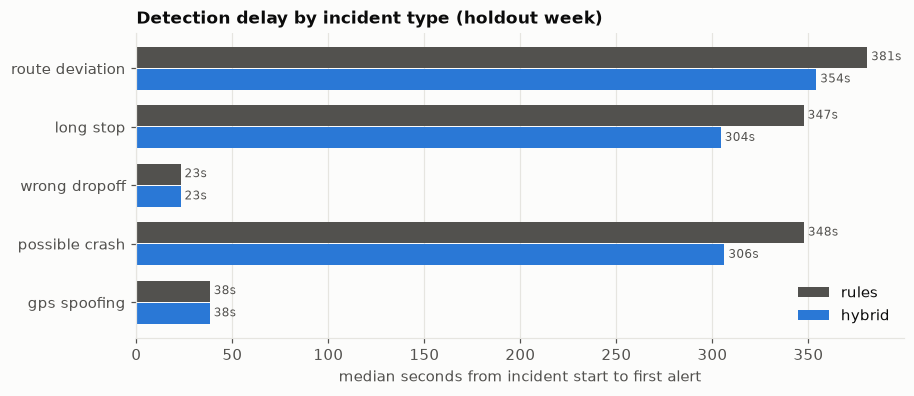

In [9]:
fig, ax = plt.subplots(figsize=(9, 3.6))
y = np.arange(len(INCIDENT_TYPES))
for k, (name, color) in enumerate([("rules", ps.NORMAL_COLOR), ("hybrid", ps.ACCENT)]):
    v = by_type[(name, "median_delay_s")].reindex(INCIDENT_TYPES)
    ax.barh(y + (k - 0.5) * 0.38, v, height=0.36, color=color, label=name)
    for yy, vv in zip(y, v):
        ax.text(vv, yy + (k - 0.5) * 0.38, f" {vv:.0f}s", va="center", fontsize=8, color=ps.INK_MUTED)
ax.set_yticks(y, [t.replace("_", " ") for t in INCIDENT_TYPES]); ax.invert_yaxis()
ax.set_xlabel("median seconds from incident start to first alert"); ax.grid(axis="y", visible=False)
ax.set_title("Detection delay by incident type (holdout week)"); ax.legend(loc="lower right")
ps.save(fig, "11_delay_by_type")

Stops and crashes are flagged sooner: the model combines *how long* the car has been still with *how* the trip got
there (speed before the stop, progress, the previous minutes), so it does not have to wait for one fixed number of
seconds. Spoofing and wrong drop-offs keep the rules' sub-minute speed.

## 5 · Explainability (SHAP)

A safety agent calling a rider must know *why* the alert fired. LightGBM's SHAP values give that per alert (reason
codes) and globally (what the model relies on).

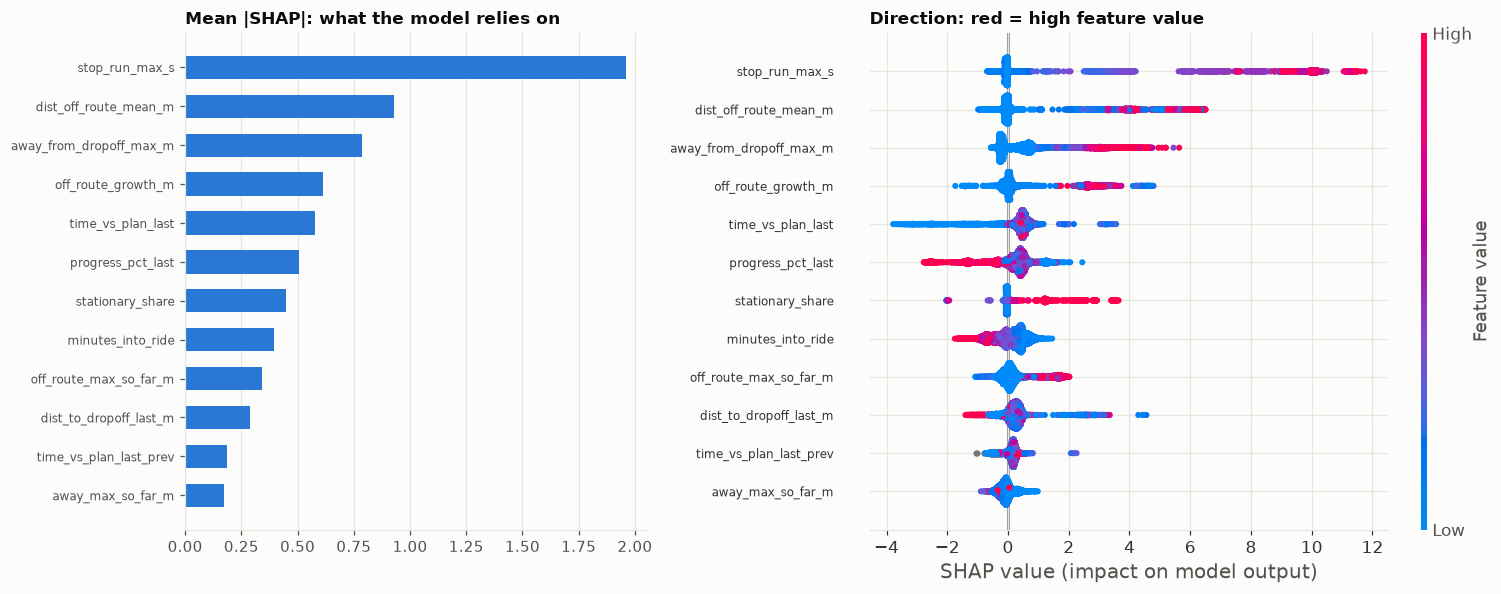

In [10]:
sample = pd.concat([hold[hold["is_incident"]], hold[~hold["is_incident"]].sample(6000, random_state=0)])
X = matrix(sample, detector.features)
explainer = shap.TreeExplainer(detector.model)
values = explainer.shap_values(X)
values = values[1] if isinstance(values, list) else values

importance = pd.Series(np.abs(values).mean(axis=0), index=detector.features).sort_values()
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [1, 1.4]})
top = importance.tail(12)
axes[0].barh(top.index, top.values, color=ps.ACCENT, height=0.6)
axes[0].set_title("Mean |SHAP|: what the model relies on"); axes[0].grid(axis="y", visible=False)
axes[0].tick_params(axis="y", labelsize=8)
plt.sca(axes[1])
shap.summary_plot(values, X, max_display=12, show=False, plot_size=None, color_bar=True)
axes[1].set_title("Direction: red = high feature value"); axes[1].tick_params(axis="y", labelsize=8)
fig.tight_layout(); ps.save(fig, "11_shap")

In [11]:
from utilities.safety_features import HISTORY_COLUMNS
history = HISTORY_COLUMNS
print(f"share of total |SHAP| from ride-history features: {importance[history].sum() / importance.sum():.0%}")

share of total |SHAP| from ride-history features: 24%


**Alerts as the safety agent sees them** (one per incident type, plus a false alarm):

In [12]:
out = detector.alerts(hold)
alerts = hold.join(out[["alert", "risk_score", "alert_source", "alert_type", "reasons"]])
first = alerts[alerts["alert"]].sort_values("window_end").groupby("ride_id").head(1)
examples = pd.concat([first[first["incident_type"] == t].head(1) for t in INCIDENT_TYPES]
                     + [first[~first["is_incident"] & ~first["after_incident"]].head(2)])
examples[["incident_type", "alert_source", "alert_type", "risk_score", "reasons"]]

,incident_type,alert_source,alert_type,risk_score,reasons
25778,route_deviation,model,route_deviation,0.993,on average 295 m off route; off-route distance grew 374 m in a minute; 388 m further from the destination
464799,long_stop,model,unexpected_stop,0.992,stopped for 290 s; standing still 100% of the minute; 17 m further from the destination
550419,wrong_dropoff,rule,wrong_dropoff,0.999,rule: trip ended far from the destination
340914,possible_crash,model,unexpected_stop,0.992,stopped for 280 s; standing still 100% of the minute; 16 m further from the destination
69367,gps_spoofing,rule,gps_spoofing,0.994,rule: physically impossible GPS jump
914527,normal,model,unexpected_stop,0.993,stopped for 290 s; standing still 100% of the minute; 11 m further from the destination
560699,normal,model,unexpected_stop,0.995,stopped for 280 s; 269 m further from the destination; 0.7x the planned trip time


## 6 · Error analysis (holdout week)

In [13]:
det = detections(alerts, hold_labels).merge(hold_labels[["incident_id", "severity", "params"]], on="incident_id")
missed = det[~det["detected"]]
print(f"missed {len(missed)} of {len(det)} incidents")
missed.groupby(["incident_type", "severity"]).size().unstack(fill_value=0)

missed 51 of 845 incidents


severity,high,low,medium
incident_type,,,
gps_spoofing,0,0,1
long_stop,0,12,0
route_deviation,11,9,18


In [14]:
# What the GPS actually showed: missed vs caught incidents
evidence = alerts[alerts["is_incident"]].groupby("incident_id").agg(
    off_route_max_m=("dist_off_route_max_m", "max"), stop_max_s=("stop_run_max_s", "max"))
evidence = det.set_index("incident_id")[["incident_type", "detected"]].join(evidence)
(evidence[evidence["incident_type"].isin(["route_deviation", "long_stop"])]
 .groupby(["incident_type", "detected"])[["off_route_max_m", "stop_max_s"]].median().round(0))

off_route_max_m  stop_max_s
incident_type   detected                             
long_stop       False                 9.0       250.0
                True                 10.0       575.0
route_deviation False               881.0        20.0
                True               1611.0        20.0

The missed deviations stayed about **900 m** from the planned route (caught ones: ~1.6 km), the same range innocent
detours and re-routes reach. The missed long stops lasted 4–4.5 minutes, shorter than some innocent stops (up to 320 s).
In GPS terms these incidents look exactly like harmless behaviour: no threshold or model on GPS alone separates them
without paging for the harmless ones too. This is the honest limit of GPS-only detection; closing it needs another
signal (in-app SOS, rider check-in, driver history).

In [15]:
fa = alerts[alerts["alert"] & ~alerts["is_incident"] & ~alerts["after_incident"]]
fa_rides = fa.groupby("ride_id")["alert_type"].first().to_frame("alert_type").join(hold_rides.set_index("ride_id"))
fa_rides["cause"] = np.select(
    [fa_rides["has_innocent_detour"], fa_rides["has_innocent_long_stop"], fa_rides["has_gps_dropout"], fa_rides["is_incident"]],
    ["innocent detour / re-route", "innocent long stop", "GPS dropout", "incident trip, before the incident"], "no hard negative")
pd.crosstab(fa_rides["alert_type"], fa_rides["cause"], margins=True)

cause,innocent detour / re-route,innocent long stop,All
alert_type,,,
route_deviation,27,0,27
unexpected_stop,0,14,14
All,27,14,41


## 7 · Findings

| # | Finding |
|---|---|
| 1 | **Hybrid vs rules, holdout week (paired bootstrap):** recall the same (+0.7 pts, not significant), false alarms **−0.55 per 1k trips (−36 %)**, median detection **45 s faster**; both significant |
| 2 | LightGBM alone loses recall on wrong drop-offs (one final window per trip, too rare to learn); the deterministic rules cover exactly that, which is why the hybrid wins |
| 3 | Isolation Forest: ~30 % recall at the same cost. It spends its budget on innocent detours and treats a standing car as normal |
| 4 | Class weighting barely mattered (PR-AUC 0.807–0.820 across the grid); shallow trees (15 leaves) generalised best |
| 5 | Ride-history features carry about a quarter of the model's signal (SHAP): one minute alone cannot tell a growing deviation from a detour turning back |
| 6 | The 51 misses (6 %) are deviations that stayed ~900 m from the route and stops of 4–4.5 min: in GPS terms identical to innocent detours and stops |
| 7 | All remaining false alarms come from the hard negatives the EDA predicted: innocent detours / re-routes (27) and innocent long stops (14) |

**Limits.** Simulated GPS and incidents; the simulator has no rain, tunnels or phone-battery behaviour, so real
precision would be lower and the threshold would need re-tuning on real feedback (agent outcomes as labels).
Next: M12 serves this detector on the live Silver windows and writes alerts to Gold.